# Metodología de generación de señales vehículo-puente

Este cuaderno explica, paso a paso, cómo la herramienta `vehicle_bridge_signal` genera la aceleración que registra un smartphone dentro de un carro que cruza un puente (monitoreo indirecto o *drive-by*), y cómo separa esa señal en sus componentes. Todo el cálculo lo hace el paquete: el cuaderno solo lo llama, muestra las ecuaciones que implementa y verifica sus resultados.

**Instalación** (desde la raíz del repositorio, con el entorno `.venv` activo):

```
pip install -e sensing-techniques/tools/vehicle-bridge-signal-generator
```

**Contenido**

1. El problema drive-by
2. Puente
3. Vehículo
4. Rugosidad del pavimento (ISO 8608)
5. Interacción vehículo-puente
6. Motor y rueda
7. Cadena de medición del smartphone
8. Descomposición exacta en componentes
9. El dataset
10. Supuestos y limitaciones

**Convenciones.** Unidades del SI. Desplazamientos y fuerzas verticales positivos hacia arriba. Todo análisis espectral sigue las convenciones de CIV E 789: método de Welch (no la FFT del registro completo), ventana Hann, 50 % de solape y `nperseg` potencia de 2 menor que el número de muestras, con resolución $\Delta f = f_s/\text{nperseg}$; agregar ceros no mejora la resolución. Los picos se leen en el bin de máxima PSD, sin interpolación.

In [1]:
import os
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import patches

import vehicle_bridge_signal as vbs
from vehicle_bridge_signal import bridge as vb_bridge
from vehicle_bridge_signal import engine as vb_engine
from vehicle_bridge_signal import roughness as vb_rough
from vehicle_bridge_signal import sensor as vb_sensor
from vehicle_bridge_signal import vehicle as vb_vehicle
from vehicle_bridge_signal.plotting import (plot_bridge_modes, plot_component_spectra, plot_components,
                                            plot_preview, plot_spectrogram)
from vehicle_bridge_signal.spectral import welch_psd

plt.rcParams.update({"figure.dpi": 85, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
SEED = 0          # base seed of every random draw in this notebook
G = vb_vehicle.G  # 9.80665 m/s^2
print("vehicle_bridge_signal", vbs.__version__, "| numpy", np.__version__)


def rms(x, mask=None):
    x = np.asarray(x, float)
    return float(np.sqrt(np.mean((x if mask is None else x[mask]) ** 2)))

vehicle_bridge_signal 1.0.0 | numpy 2.5.4


## 1. El problema drive-by

En el monitoreo indirecto, un vehículo instrumentado cruza el puente y su respuesta se usa para identificar propiedades del puente, como sus frecuencias naturales. Aquí el instrumento es un **smartphone** apoyado en la carrocería de un carro común, como se discutió en CIV E 789 (Lecture 2): es barato y abundante, pero mide una señal en la que el puente es solo una de muchas contribuciones.

La aceleración vertical que registra el teléfono mezcla:

- la **respuesta del puente**: el puente se deflecta bajo el vehículo y vibra en sus modos; el vehículo "siente" esa deflexión en el punto de contacto de la llanta;
- la **dinámica de la suspensión**: el vehículo amplifica lo que ocurre cerca de sus propias frecuencias (rebote de la carrocería, salto de la rueda) y filtra el resto;
- la **rugosidad del pavimento**, que excita al vehículo en todo el cruce, dentro y fuera del puente;
- la **vibración del motor**, armónica y de alta frecuencia;
- el **ruido del sensor** y los efectos de la adquisición (filtro anti-alias, muestreo, cuantización).

El reto, que es el centro del proyecto de CIV E 779, es separar la contribución del puente de la suspensión, la rugosidad, el motor y el ruido. Para entrenar y evaluar métodos de separación hace falta la verdad de referencia, y en mediciones reales no existe. Por eso la herramienta genera las señales por simulación física y entrega, además de la medición, **cada componente por separado**.

El esquema resume el modelo: viga simplemente apoyada, cuarto de carro con masa suspendida $m_s$ (carrocería) y no suspendida $m_u$ (eje y rueda), suspensión $(k_s, c_s)$, llanta $(k_t, c_t)$ y teléfono sobre la carrocería. El vehículo parte antes del puente, cruza a velocidad constante $v$ y sigue después; la rugosidad cubre todo el recorrido.

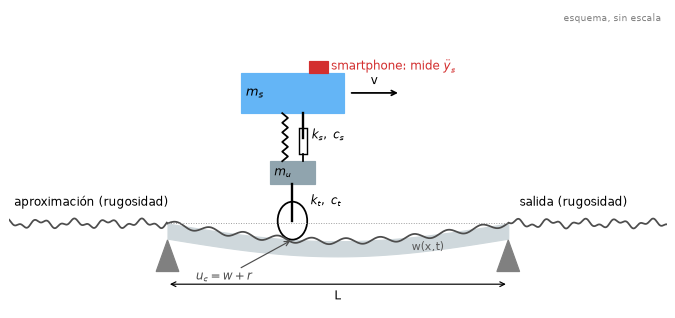

In [2]:
def draw_schematic(ax):
    # Not to scale: the vertical axis is exaggerated so the vehicle is readable next to a 30 m span.
    x = np.linspace(-14, 44, 800)
    road = 0.12 * np.sin(2.1 * x) + 0.08 * np.sin(5.3 * x + 1)
    ax.plot(x[x < 0], road[x < 0], color="0.3")
    ax.plot(x[x > 30], road[x > 30], color="0.3")
    xb = np.linspace(0, 30, 300)
    defl = -0.7 * np.sin(np.pi * xb / 30)
    ax.fill_between(xb, defl - 0.6, defl, color="#cfd8dc")
    ax.plot(xb, defl + 0.12 * np.sin(2.1 * xb), color="0.3")
    ax.plot(xb, np.zeros_like(xb), color="0.6", ls=":", lw=0.8)
    ax.text(21.5, -1.05, "w(x,t)", fontsize=9, color="0.35")
    for xs in (0, 30):
        ax.add_patch(patches.Polygon([[xs, -0.65], [xs - 1.0, -1.9], [xs + 1.0, -1.9]], color="0.5"))
    ax.annotate("", xy=(30, -2.4), xytext=(0, -2.4), arrowprops=dict(arrowstyle="<->"))
    ax.text(15, -3.0, "L", ha="center")
    xc = 11.0
    yr = -0.7 * np.sin(np.pi * xc / 30)                     # contact point on the deflected deck
    ax.add_patch(patches.Ellipse((xc, yr + 0.75), 2.6, 1.5, fill=False, lw=1.5))
    ax.plot([xc, xc], [yr + 0.75, yr + 2.2], color="k", lw=2)
    ax.text(xc + 1.6, yr + 1.4, r"$k_t,\ c_t$", fontsize=10)
    ax.add_patch(patches.Rectangle((xc - 2.0, yr + 2.2), 4.0, 0.9, color="#90a4ae"))
    ax.text(xc - 1.6, yr + 2.65, r"$m_u$", va="center", fontsize=10)
    zz = np.linspace(yr + 3.1, yr + 5.0, 11)
    ax.plot(xc - 0.9 + 0.5 * (np.arange(11) % 2), zz, color="k")
    ax.add_patch(patches.Rectangle((xc + 0.55, yr + 3.4), 0.7, 1.0, fill=False, lw=1.2))
    ax.plot([xc + 0.9, xc + 0.9], [yr + 3.1, yr + 3.4], color="k")
    ax.plot([xc + 0.9, xc + 0.9], [yr + 4.0, yr + 5.0], color="k", lw=2)
    ax.text(xc + 1.7, yr + 4.0, r"$k_s,\ c_s$", fontsize=10)
    ax.add_patch(patches.Rectangle((xc - 4.5, yr + 5.0), 9.0, 1.6, color="#64b5f6"))
    ax.text(xc - 4.1, yr + 5.8, r"$m_s$", va="center", fontsize=11)
    ax.add_patch(patches.Rectangle((xc + 1.5, yr + 6.6), 1.6, 0.45, color="#d32f2f"))
    ax.text(xc + 3.4, yr + 6.85, r"smartphone: mide $\ddot y_s$", color="#d32f2f", va="center")
    ax.annotate("", xy=(xc + 9.5, yr + 5.8), xytext=(xc + 5.0, yr + 5.8), arrowprops=dict(arrowstyle="->", lw=1.5))
    ax.text(xc + 7.2, yr + 6.15, "v", ha="center")
    ax.annotate(r"$u_c = w + r$", xy=(xc, yr), xytext=(xc - 8.5, yr - 1.6),
                arrowprops=dict(arrowstyle="->", color="0.3"), color="0.3")
    ax.text(-13.5, 0.7, "aproximación (rugosidad)")
    ax.text(31, 0.7, "salida (rugosidad)")
    ax.text(43.5, 8.0, "esquema, sin escala", ha="right", fontsize=8, color="0.5")
    ax.set_xlim(-14, 44)
    ax.set_ylim(-3.4, 8.5)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(10, 4.6))
draw_schematic(ax)
plt.show()

### Un primer cruce

El preset `typical_car_smartphone` es un escenario fijo: un carro de 450 kg (cuarto de carro) cruza un puente de 30 m ($f_1 = 3.63$ Hz) a 15 m/s sobre un pavimento clase B, con un motor de 4 cilindros a 1500 rpm y un acelerómetro típico de smartphone. Con `simulate(config, seed)` se obtiene la señal medida y sus componentes.

Puente: L = 30 m, f1 = 3.63 Hz | vehículo: 450 kg, frecuencias [ 1.4  11.02] Hz | v = 15 m/s, mu = 0.0015
componente              RMS sobre el puente [m/s²]
bridge_mode_1                             9.96e-04
bridge_mode_2                             1.64e-04
bridge_mode_3                             4.46e-05
bridge_higher_modes                       0.00e+00
roughness                                 5.14e-01
engine                                    1.86e-02
wheel                                     0.00e+00
noise                                     1.20e-02


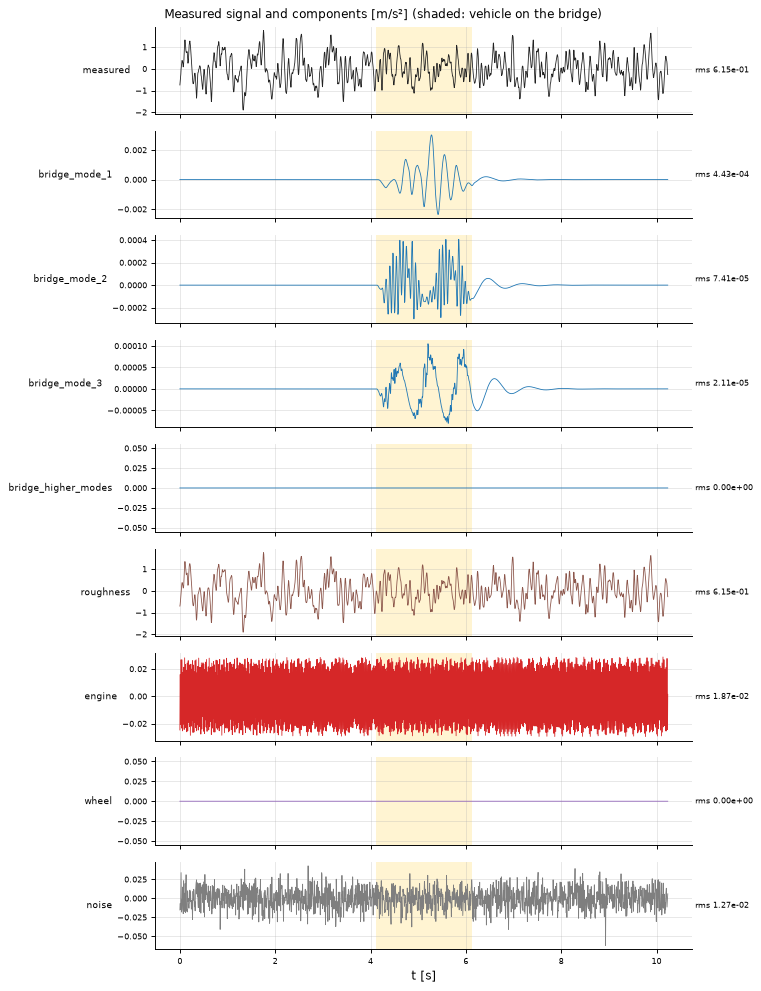

In [3]:
res = vbs.simulate("typical_car_smartphone", seed=SEED)
m = res.metadata
print(f"Puente: L = {m['span']:.0f} m, f1 = {m['f1']:.2f} Hz | vehículo: {m['vehicle_mass']:.0f} kg, "
      f"frecuencias {np.round(m['vehicle_frequencies'], 2)} Hz | v = {m['speed']:.0f} m/s, mu = {m['mass_ratio']:.4f}")
print(f"{'componente':<22}{'RMS sobre el puente [m/s²]':>28}")
for k, v in res.components.items():
    print(f"{k:<22}{rms(v, res.on_bridge):>28.2e}")
fig = plot_components(res)
plt.show()

La componente del puente (suma de `bridge_mode_*`) tiene una RMS del orden de $10^{-3}$ m/s², mientras que la respuesta a la rugosidad es del orden de $0.5$ m/s²: unos 54 dB por encima. El motor y el ruido del sensor también superan al puente. En la señal medida (arriba) el puente es invisible a simple vista. Esta es la dificultad que deben resolver los métodos de separación, y la razón de que la herramienta guarde cada componente como verdad de referencia. Las secciones siguientes explican de dónde sale cada componente.

## 2. Puente

El puente se modela como una viga de Euler-Bernoulli simplemente apoyada, por superposición modal. Las formas modales, las frecuencias y la masa modal son:

$$\phi_n(x)=\sin\frac{n\pi x}{L},\qquad \omega_n=\left(\frac{n\pi}{L}\right)^2\sqrt{\frac{EI}{\bar m}},\qquad M_n=\frac{\bar m L}{2} \tag{1}$$

$\phi_n$ es la forma del modo $n$ (vale cero fuera de $0 \le x \le L$), $L$ la luz, $EI$ la rigidez a flexión y $\bar m$ la masa por unidad de longitud. De (1) se sigue $f_n = n^2 f_1$. La herramienta parametriza el puente por $L$, $f_1$ y $\bar m$, que son las cantidades con rangos publicados, y deriva la rigidez despejando $EI$ de (1) con $n = 1$:

$$EI = \bar m\left(\frac{2L^2 f_1}{\pi}\right)^2 \tag{2}$$

Si no se da $f_1$, se toma un valor nominal interpolado en log-log a partir de la tabla 5 de Talebi-Kalaleh & Mei (2026) (15 m → 8.03 Hz, 30 m → 3.63 Hz, 50 m → 2.05 Hz, 100 m → 0.75 Hz), multiplicado por un factor aleatorio U[0.7, 1.3] [SUPUESTO]. Se incluyen los modos con $f_n \le f_{\max}$, por defecto $\min(0.45 f_{s,\text{out}}, 40\ \text{Hz})$, con un máximo de 6.

**Convención de signos.** Los desplazamientos son positivos hacia arriba y las fuerzas verticales también: el peso $W$ de un eje entra al puente como una fuerza $P = -W$. Cada coordenada modal $q_n$ cumple

$$\ddot q_n+2\zeta_n\omega_n\dot q_n+\omega_n^2 q_n=\frac{1}{M_n}\sum_{a}\phi_n\big(x_a(t)\big)\,P_a(t)\,\mathbb{1}\big[0\le x_a(t)\le L\big] \tag{3}$$

donde $x_a(t)$ es la posición del eje $a$, $P_a$ la fuerza que el eje aplica sobre el puente y $\zeta_n$ el amortiguamiento del modo $n$, distinto para cada modo (U[0.5 %, 3 %] [SUPUESTO]). La deflexión es la suma modal

$$w(x,t)=\sum_n\phi_n(x)\,q_n(t) \tag{4}$$

L = 30.0 m, m = 10000.0 kg/m, f1 nominal = 3.63 Hz -> EI = 4.326e+10 N m², M_n = 150000 kg
  modo 1: f =   3.63 Hz  (= 1^2 f1)   omega =   22.81 rad/s
  modo 2: f =  14.52 Hz  (= 2^2 f1)   omega =   91.23 rad/s
  modo 3: f =  32.67 Hz  (= 3^2 f1)   omega =  205.27 rad/s


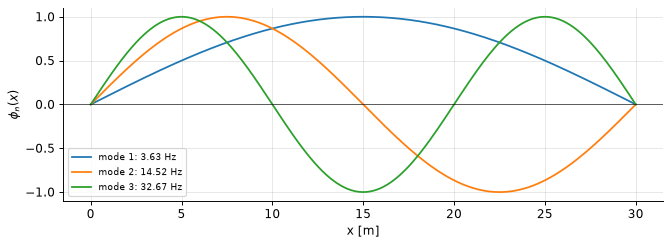

In [4]:
L, m_bar = 30.0, 10000.0
f1 = vb_bridge.nominal_f1(L)
n_modes = vb_bridge.count_modes(f1, vb_bridge.resolve_f_max("auto", 200.0), 6)
b = vbs.Bridge(L, f1, m_bar, [0.015] * n_modes)
print(f"L = {L} m, m = {m_bar} kg/m, f1 nominal = {f1:.2f} Hz -> EI = {b.flexural_rigidity:.3e} N m², "
      f"M_n = {b.modal_mass:.0f} kg")
for n, (fn, wn) in enumerate(zip(b.frequencies, b.omegas), start=1):
    print(f"  modo {n}: f = {fn:6.2f} Hz  (= {n}^2 f1)   omega = {wn:7.2f} rad/s")
fig = plot_bridge_modes(b)
plt.show()

Con $f_{\max} = 40$ Hz entran tres modos (3.63, 14.5 y 32.7 Hz). El cuarto, a 58 Hz, quedaría por encima del límite.

**Verificación de signos y masa modal.** Bajo una carga estática $P$ en el centro, (3) da $q_n = \phi_n(L/2)P/(M_n\omega_n^2)$, y la serie (4) converge a la solución de resistencia de materiales:

$$w(L/2) = \frac{2PL^3}{\pi^4 EI}\sum_{n\ \text{impar}} \frac{1}{n^4} = \frac{PL^3}{48EI} \tag{5}$$

porque $\sum_{n\ \text{impar}} n^{-4} = \pi^4/96$. La deflexión depende de $P$, $L$ y $EI$, y sirve para confirmar el signo (una carga hacia abajo, $P<0$, debe dar $w<0$) y el valor de $M_n$.

In [5]:
W = 1200 * G
exact = b.exact_midspan_static_deflection(-W)
print(f"PL^3/(48EI) con P = -W = {-W:.0f} N: {exact * 1e3:.5f} mm")
for n in (1, 3, 5, 15, 41):
    bn = vbs.Bridge(L, f1, m_bar, np.zeros(n))
    w = bn.static_deflection(L / 2, L / 2, -W)
    print(f"  {n:2d} modos: w(L/2) = {w * 1e3:.5f} mm   error relativo = {abs(w / exact - 1):.2e}")

PL^3/(48EI) con P = -W = -11768 N: -0.15303 mm
   1 modos: w(L/2) = -0.15081 mm   error relativo = 1.45e-02
   3 modos: w(L/2) = -0.15267 mm   error relativo = 2.30e-03
   5 modos: w(L/2) = -0.15292 mm   error relativo = 7.22e-04
  15 modos: w(L/2) = -0.15302 mm   error relativo = 3.98e-05
  41 modos: w(L/2) = -0.15303 mm   error relativo = 2.21e-06


La deflexión es negativa (hacia abajo) y el error decae como la cola de $\sum n^{-4}$: con un solo modo ya se tiene el 98.6 % del valor exacto. La prueba automática `test_static_midspan_deflection_converges_to_closed_form` verifica que el error coincide con esa cola.

## 3. Vehículo

El modelo por defecto es el **cuarto de carro** de dos grados de libertad (ecuación 3 de Talebi-Kalaleh & Mei, 2026), al que se añade la fuerza del motor $F_e$ sobre la carrocería:

$$\begin{bmatrix} m_u&0\\0&m_s\end{bmatrix}\begin{Bmatrix}\ddot y_u\\ \ddot y_s\end{Bmatrix}+\begin{bmatrix}c_t+c_s&-c_s\\-c_s&c_s\end{bmatrix}\begin{Bmatrix}\dot y_u\\ \dot y_s\end{Bmatrix}+\begin{bmatrix}k_t+k_s&-k_s\\-k_s&k_s\end{bmatrix}\begin{Bmatrix}y_u\\ y_s\end{Bmatrix}=\begin{Bmatrix}c_t\dot u_c+k_t u_c\\ F_e(t)\end{Bmatrix} \tag{6}$$

$y_u$ e $y_s$ son los desplazamientos del eje y de la carrocería medidos desde el equilibrio estático (así la gravedad se cancela), y $u_c$ es el desplazamiento del punto de contacto de la llanta (sección 5). La señal principal es la aceleración de la carrocería, $\ddot y_s$, que es lo que mide el teléfono. También están disponibles:

- `sprung_mass` (Yang et al., 2004): una sola masa sobre un resorte y un amortiguador que tocan el pavimento directamente;
- `half_car`: carrocería con rebote $y_v$ y cabeceo $\theta$ (positivo con la nariz hacia arriba) y dos ejes. Un punto de la carrocería a una distancia $x$ delante del centro de gravedad se mueve $y_v + x\theta$, así que el teléfono en $x_p$ mide $\ddot y_v + x_p\ddot\theta$.

**Rigideces a partir de frecuencias objetivo.** La sección 6 da rangos de frecuencia de rebote $f_b$ y de salto de rueda $f_w$, no rigideces. Con las definiciones de Gillespie (1992), la *ride rate* y el salto de rueda son

$$\frac{k_s k_t}{k_s+k_t} = m_s(2\pi f_b)^2,\qquad k_s+k_t = m_u(2\pi f_w)^2 \tag{7}$$

Entonces $k_s$ y $k_t$ son las raíces de $z^2 - az + ab = 0$, con $a = m_u(2\pi f_w)^2$ y $b = m_s(2\pi f_b)^2$; la llanta toma la raíz mayor. Hay solución real solo si $a \ge 4b$, es decir, si $(m_u/m_s)(f_w/f_b)^2 \ge 4$. En el muestreo aleatorio las combinaciones imposibles se vuelven a muestrear. El amortiguamiento de la suspensión es $c_s = 2\zeta_s\sqrt{k_s m_s}$ y el de la llanta es $c_t = 0$, como en los benchmarks de referencia. Las frecuencias propias reales del sistema de 2 GDL difieren un poco de las objetivo y son las que se guardan en los metadatos.

In [6]:
car = vbs.quarter_car(body_mass=400.0, unsprung_mass=50.0, body_frequency=1.4, wheel_frequency=11.0,
                      suspension_damping_ratio=0.3)
p = car.parameters
print(f"k_s = {p['suspension_stiffness']:.0f} N/m, k_t = {p['tyre_stiffness']:.0f} N/m, c_s = {p['suspension_damping']:.0f} N s/m")
print("frecuencias propias reales [Hz]:", np.round(car.natural_frequencies(), 3), " (objetivo 1.4 y 11.0)")
print("amortiguamiento modal [-]:", np.round(car.modal_damping_ratios(), 3))
try:
    vb_vehicle.quarter_car_stiffnesses(500.0, 30.0, 2.0, 8.0)
except vbs.ConfigError as exc:
    print("Combinación imposible ->", str(exc)[:110], "...")

k_s = 36542 N/m, k_t = 202303 N/m, c_s = 2294 N s/m
frecuencias propias reales [Hz]: [ 1.398 11.016]  (objetivo 1.4 y 11.0)
amortiguamiento modal [-]: [0.235 0.35 ]
Combinación imposible -> No positive stiffnesses give f_body=2 Hz and f_wheel=8 Hz with m_s=500 kg, m_u=30 kg: it needs (m_u/m_s)(f_whe ...


**Función de respuesta en frecuencia.** Si el contacto se mueve armónicamente, $u_c = U e^{i\omega t}$, la aceleración de la carrocería en régimen permanente es $\ddot y_s = H(\omega)\,U e^{i\omega t}$ con

$$H(\omega) = -\omega^2\, \mathbf{s}^T\left(\mathbf{K}-\omega^2\mathbf{M}+i\omega\mathbf{C}\right)^{-1}\mathbf{b}\,(k_t + i\omega c_t) \tag{8}$$

donde $\mathbf{M}, \mathbf{C}, \mathbf{K}$ son las matrices de (6), $\mathbf{b}$ selecciona el grado de libertad del eje y $\mathbf{s}$ el del sensor. El cociente $|H|/\omega^2$ es la transmisibilidad: cuántas veces la carrocería amplifica la aceleración del contacto. Esta función es el operador $\mathcal{G}$ de la sección 8, que convierte el desplazamiento del contacto en aceleración de la carrocería.

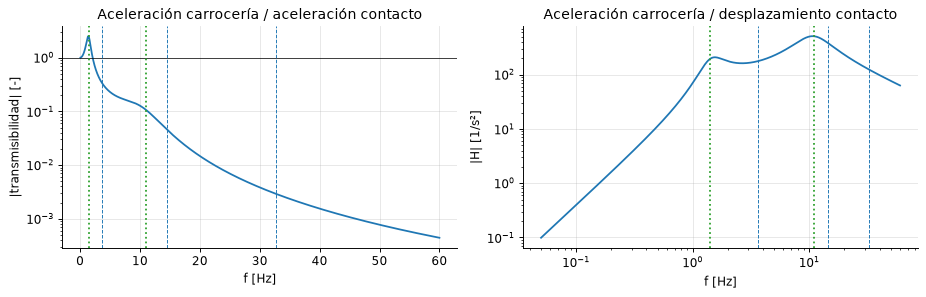

In [7]:
f = np.linspace(0.05, 60, 3000)
h = car.frf_contact_to_sensor(f)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].semilogy(f, np.abs(h) / (2 * np.pi * f) ** 2)
axs[0].axhline(1, color="k", lw=0.6)
axs[0].set(xlabel="f [Hz]", ylabel="|transmisibilidad| [-]", title="Aceleración carrocería / aceleración contacto")
axs[1].loglog(f, np.abs(h))
axs[1].set(xlabel="f [Hz]", ylabel="|H| [1/s²]", title="Aceleración carrocería / desplazamiento contacto")
for ax in axs:
    for fv in car.natural_frequencies():
        ax.axvline(fv, color="tab:green", ls=":")
    for fb in b.frequencies:
        ax.axvline(fb, color="tab:blue", ls="--", lw=0.8)
plt.tight_layout()
plt.show()

Las líneas verdes son las frecuencias del vehículo y las azules las del puente de la sección 2. Cerca del rebote (1.4 Hz) la carrocería amplifica la entrada, entre el rebote y el salto de rueda la transmisibilidad cae por debajo de 1, y por encima del salto de rueda (11 Hz) el vehículo filtra fuertemente. Una frecuencia del puente que cae lejos de la resonancia del vehículo llega atenuada a la carrocería. La rugosidad, en cambio, tiene su energía a baja frecuencia espacial y el vehículo la amplifica cerca de su propio rebote. Por eso, en el espectro de la medición, el vehículo domina y el puente queda escondido.

## 4. Rugosidad del pavimento (ISO 8608)

La norma ISO 8608 describe el perfil por su densidad espectral de desplazamiento (unilateral) en función de la frecuencia espacial $n$ (ciclos/m):

$$G_d(n)=G_d(n_0)\left(\frac{n}{n_0}\right)^{-w},\qquad n_0=0.1\ \text{ciclos/m} \tag{9}$$

$G_d(n_0)$ [m³] define la clase del pavimento y $w$ es la ondulación (*waviness*), igual a 2 según la norma. En vías reales $w$ varía entre 1.5 y 3.5, con media cercana a 2.5 (Loprencipe y Zoccali, 2017); la herramienta permite cambiarlo.

**Tabla de clases y una discrepancia.** Hay dos convenciones. Con $n_0 = 0.1$ ciclos/m, las medias geométricas son A = 16, B = 64, C = 256 y D = 1024 ×10⁻⁶ m³, con límites A < 32, B 32–128, C 128–512 y D 512–2048 (Agostinacchio et al., 2014, tabla 1). Con la frecuencia angular $\Omega_0 = 1$ rad/m, los valores son 1, 4, 16 y 64 ×10⁻⁶ m³. Las dos son equivalentes: como $G_d(\Omega) = G_d(n)/(2\pi)$ y $\Omega_0 = 1$ rad/m corresponde a $n = 1/(2\pi) = 0.159$ ciclos/m,

$$G_d(\Omega_0) = \frac{1}{2\pi}\,G_d(n_0)\left(\frac{0.159}{0.1}\right)^{-2} = 0.0633\,G_d(n_0) \approx \frac{G_d(n_0)}{16} \tag{10}$$

La tabla 1 de Talebi-Kalaleh & Mei (2026) muestra los valores 1, 4, 16, 64 y 256, pero los etiqueta con $n_0 = 0.1$ ciclos/m: mezcla las dos convenciones. Si se usaran así, cada clase sería 16 veces más suave en PSD (4 veces en amplitud). La herramienta usa **la convención en ciclos/m con 16, 64, 256 y 1024**. La celda siguiente muestra la clase real que tendrían los valores de esa tabla.

In [8]:
print(f"{'clase':<6}{'G_d(n0) [1e-6 m3]':>20}{'límites [1e-6 m3]':>22}{'G_d(Omega0) equiv.':>22}")
for c in "ABCDE":
    lo, hi = vbs.class_bounds(c)
    gd = vb_rough.class_mean(c)
    print(f"{c:<6}{gd * 1e6:>20.0f}{f'{lo * 1e6:.0f} - {hi * 1e6:.0f}':>22}{gd * 0.0633 * 1e6:>22.2f}")
print("\nValores de la tabla 1 de Talebi-Kalaleh & Mei (2026) leídos con n0 = 0.1 ciclos/m:")
for label, val in zip("ABCDE", (1, 4, 16, 64, 256)):
    print(f"  '{label}' = {val:>3} e-6 m3  -> clase ISO real: {vbs.classify(val * 1e-6)}")

clase    G_d(n0) [1e-6 m3]     límites [1e-6 m3]    G_d(Omega0) equiv.
A                       16                8 - 32                  1.01
B                       64              32 - 128                  4.05
C                      256             128 - 512                 16.20
D                     1024            512 - 2048                 64.82
E                     4096           2048 - 8192                259.28

Valores de la tabla 1 de Talebi-Kalaleh & Mei (2026) leídos con n0 = 0.1 ciclos/m:
  'A' =   1 e-6 m3  -> clase ISO real: A
  'B' =   4 e-6 m3  -> clase ISO real: A
  'C' =  16 e-6 m3  -> clase ISO real: A
  'D' =  64 e-6 m3  -> clase ISO real: B
  'E' = 256 e-6 m3  -> clase ISO real: C


**Generación.** El perfil se genera como suma de armónicos con fases aleatorias uniformes en $[0, 2\pi)$ (ecuación 8 de Talebi-Kalaleh & Mei, 2026):

$$r(x)=\sum_{i}\sqrt{2\,G_d(n_i)\,\Delta n}\;\cos\left(2\pi n_i x+\varphi_i\right),\qquad n_i = i\,\Delta n \in [n_l, n_u] \tag{11}$$

con $n_l = 0.01$ y $n_u = 10$ ciclos/m. La amplitud de cada armónico depende de la PSD en su frecuencia y del paso $\Delta n$; así la varianza del perfil es $\int G_d\,dn$. El perfil es periódico con periodo $1/\Delta n$. La herramienta fija $1/\Delta n = 2048$ m, que es más del doble de cualquier distancia recorrida en la ventana (en todo caso se duplica automáticamente si no alcanza). Además, ese periodo no depende de la velocidad, así que **un mismo perfil sirve para cruces a distintas velocidades**, lo que hace falta para estudios paramétricos.

Las derivadas son las del mismo sumatorio, de forma analítica:

$$r'(x)=-\sum_i A_i\,2\pi n_i\,\sin(2\pi n_i x+\varphi_i),\qquad \dot r = v\,r'(x),\qquad \ddot r = v^2 r''(x) \tag{12}$$

Usar estas derivadas, y no diferencias finitas del desplazamiento, evita aceleraciones espurias en el contacto.

**Evaluación.** El paquete evalúa (11) de dos formas equivalentes: por suma directa vectorizada, para posiciones arbitrarias, y sobre la malla uniforme de la simulación con una transformada chirp-z (algoritmo de Bluestein). Esta última es una generalización de la IFFT para cualquier paso $\Delta x$ y es la que se usa en la simulación. Cuando $\Delta x$ divide exactamente el periodo, coincide con una IFFT.

20460 armónicos; diferencia máxima chirp-z vs suma directa: 6.8e-13 (relativa)


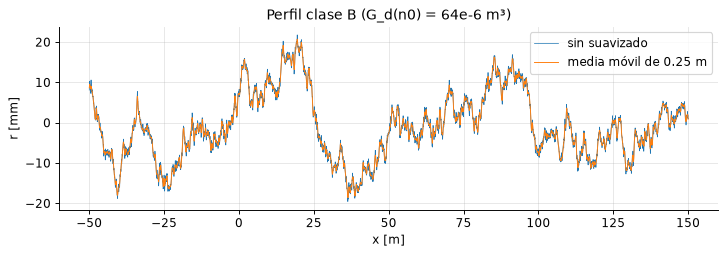

In [9]:
prof = vbs.RoughnessProfile.generate(np.random.default_rng(SEED), gd_n0=64e-6, period=2048.0)
x0, dx, n = -50.0, 0.01, 20000
fast = prof.evaluate_uniform(x0, dx, n)                  # chirp-z (used by the simulation)
direct = prof.evaluate(x0 + dx * np.arange(n))           # direct sum
print(f"{prof.n_harmonics} armónicos; diferencia máxima chirp-z vs suma directa: "
      f"{np.max(np.abs(fast - direct)) / np.max(np.abs(direct)):.1e} (relativa)")
smooth = vbs.RoughnessProfile.generate(np.random.default_rng(SEED), gd_n0=64e-6, period=2048.0, smoothing_length=0.25)
x = x0 + dx * np.arange(n)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(x, fast * 1e3, lw=0.6, label="sin suavizado")
ax.plot(x, smooth.evaluate_uniform(x0, dx, n) * 1e3, lw=0.8, label="media móvil de 0.25 m")
ax.set(xlabel="x [m]", ylabel="r [mm]", title="Perfil clase B (G_d(n0) = 64e-6 m³)")
ax.legend()
plt.show()

**Verificación de la PSD y de la clase.** Se generan perfiles largos de las clases A a D, se estima su PSD con Welch y se compara con (9). La clase se estima promediando $\hat G(n)\,(n/n_0)^w$ en la banda 0.05–5 ciclos/m.

clase A: G_d(n0) pedido     16e-6, estimado    16.0e-6 -> clase A, w ajustado = 2.00


clase B: G_d(n0) pedido     64e-6, estimado    63.9e-6 -> clase B, w ajustado = 2.00
clase C: G_d(n0) pedido    256e-6, estimado   255.5e-6 -> clase C, w ajustado = 2.00
clase D: G_d(n0) pedido   1024e-6, estimado  1022.1e-6 -> clase D, w ajustado = 2.00


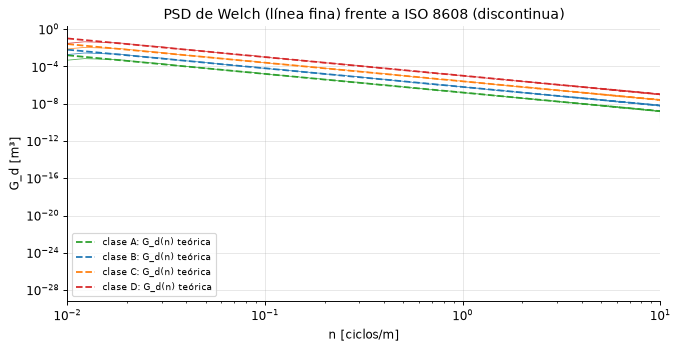

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.2))
dxp = 0.02
for c, color in zip("ABCD", ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
    gd = vb_rough.class_mean(c)
    pr = vbs.RoughnessProfile.generate(np.random.default_rng(1), gd, period=4096.0)
    r = pr.evaluate_uniform(0.0, dxp, int(4096 / dxp))
    est = vb_rough.estimate_gd_n0(r, dxp, band=(0.05, 5.0), nperseg=8192)
    sel = est["n"] > 0
    ax.loglog(est["n"][sel], est["psd"][sel], color=color, lw=0.7, alpha=0.8)
    nn = np.logspace(-2, 1, 50)
    ax.loglog(nn, vbs.displacement_psd(nn, gd), color=color, ls="--", lw=1.5, label=f"clase {c}: G_d(n) teórica")
    print(f"clase {c}: G_d(n0) pedido {gd * 1e6:6.0f}e-6, estimado {est['gd_n0'] * 1e6:7.1f}e-6 -> "
          f"clase {est['class']}, w ajustado = {est['waviness_fit']:.2f}")
ax.set(xlabel="n [ciclos/m]", ylabel="G_d [m³]", xlim=(0.01, 10), title="PSD de Welch (línea fina) frente a ISO 8608 (discontinua)")
ax.legend(fontsize=8)
plt.show()

**Suavizado por la huella de la llanta.** Una llanta no sigue ondulaciones mucho más cortas que su huella. Se modela con una media móvil centrada de longitud $\ell$ (0.25 m por defecto [SUPUESTO], como el suavizado del framework de referencia), que equivale a multiplicar cada armónico por

$$\operatorname{sinc}(n\ell)=\frac{\sin(\pi n \ell)}{\pi n \ell} \tag{13}$$

El factor depende solo de $n$ y $\ell$, y elimina casi por completo las longitudes de onda menores que $\ell$. Al aplicarlo en el espectro, las derivadas (12) siguen siendo exactas.

**Del espacio al tiempo.** A velocidad constante, $x = vt$, la frecuencia temporal es $f = v\,n$ y la PSD temporal es

$$G_t(f)=\frac{1}{v}\,G_d\!\left(\frac{f}{v}\right) \tag{14}$$

Con $w = 2$, a una frecuencia temporal fija, $G_t(f) = G_d(n_0)\,n_0^2\,v/f^2$ crece linealmente con $v$. Por eso, a mayor velocidad, la rugosidad excita más al vehículo en la banda de sus propias frecuencias.

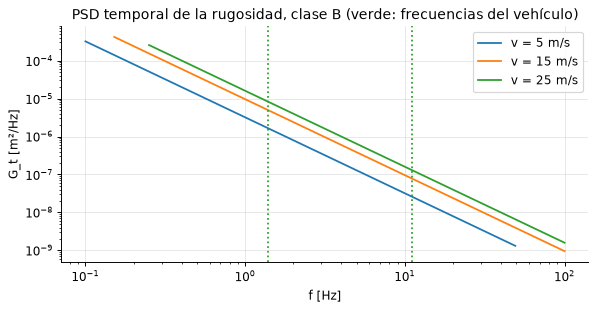

In [11]:
f = np.logspace(-1, 2, 400)
fig, ax = plt.subplots(figsize=(8, 3.6))
for v in (5.0, 15.0, 25.0):
    band = (f / v >= 0.01) & (f / v <= 10)
    ax.loglog(f[band], vb_rough.temporal_psd(f[band], v, 64e-6), label=f"v = {v:.0f} m/s")
for fv in car.natural_frequencies():
    ax.axvline(fv, color="tab:green", ls=":")
ax.set(xlabel="f [Hz]", ylabel="G_t [m²/Hz]", title="PSD temporal de la rugosidad, clase B (verde: frecuencias del vehículo)")
ax.legend()
plt.show()

## 5. Interacción vehículo-puente

**Desplazamiento del contacto.** Cada eje está sobre el puente, que se deflecta, y sobre el perfil de rugosidad:

$$u_c(t)=w\big(x_a(t),t\big)+r\big(x_a(t)\big)=\sum_n\phi_n(x_a)\,q_n(t)+r(x_a) \tag{15}$$

Su velocidad se calcula con la regla de la cadena, de forma analítica, nunca derivando $u_c$ numéricamente:

$$\dot u_c=\sum_n\Big[\phi_n(x_a)\,\dot q_n+v\,\phi_n'(x_a)\,q_n\Big]+v\,r'(x_a) \tag{16}$$

**Fuerza sobre el puente.** La fuerza que el eje aplica sobre el puente (positiva hacia arriba) es el peso estático más la fuerza dinámica de la llanta:

$$P_a=-W_a+k_t\,(y_u-u_c)+c_t\,(\dot y_u-\dot u_c) \tag{17}$$

La fuerza de contacto (compresión) es $-P_a$. Si se vuelve negativa, la rueda se despega del pavimento. El modelo lineal no lo representa, así que la herramienta lo registra como advertencia y guarda la relación mínima entre la fuerza de contacto y la carga estática (`min_contact_force_ratio`).

**Modo acoplado.** Se resuelven juntos los modos del puente y los grados de libertad del vehículo. Al sustituir (15)–(17) en (3) y (6) queda un sistema $\mathbf{M}\ddot{\mathbf{X}}+\mathbf{C}(t)\dot{\mathbf{X}}+\mathbf{K}(t)\mathbf{X}=\mathbf{F}(t)$, con $\mathbf{X} = [q_1 \dots q_N, y_u, y_s]^T$, cuyas matrices cambian mientras el eje recorre el puente. En cada paso se ensamblan e integran con **Newmark de aceleración promedio** ($\gamma = 1/2$, $\beta = 1/4$), de forma implícita. Como el sistema es lineal en las entradas, se resuelve en una sola pasada con una columna por cada fuente de excitación (peso, rugosidad, rueda, motor y vibración ambiental). Eso se aprovecha en la sección 8.

**Modo desacoplado** (algoritmo 2 de Talebi-Kalaleh & Mei, 2026). El peso actúa como carga móvil sobre el puente, y luego la deflexión resultante más la rugosidad excitan al vehículo. Es exacto cuando la masa del vehículo tiende a cero. Su precisión depende de la relación de masas

$$\mu=\frac{m_v}{\bar m L} \tag{18}$$

que se guarda en los metadatos.

**Benchmark de Yang et al. (2004).** Puente de 25 m con $EI = 2.75\times10^{10}\cdot 0.12$ N m² y $\bar m = 4800$ kg/m, sin amortiguamiento ($f_{b1} = 2.08$ Hz); masa suspendida de 1200 kg con $k = 5\times10^5$ N/m ($f_v = 3.25$ Hz); 10 m/s; pavimento liso. Se compara con el framework de los profesores, `OpenSees-VBI-Simulation` (configuración `quarter_car_simple_Yang2004`, modelo de elementos finitos con acoplamiento iterativo). Su resultado se generó una vez y está guardado en `tests/reference/`.

coupled   puente: R² = 0.99999
coupled   vehículo: R² = 0.99997


decoupled puente: R² = 0.99999
decoupled vehículo: R² = 0.99997
Commit del framework de referencia: abbe91fcf99cfc0fe3cbf66ec9e156a3f9e9b19f


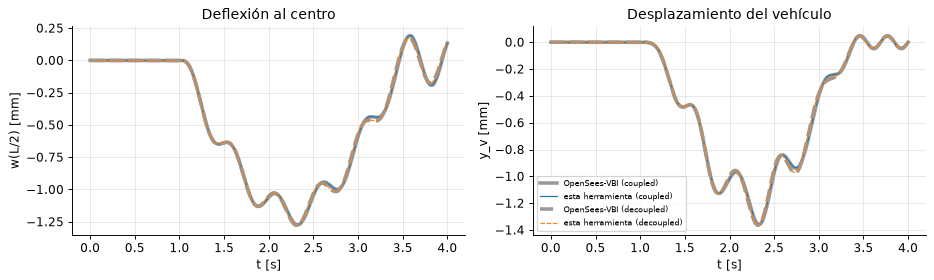

In [12]:
ref = np.load(Path("..") / "tests" / "reference" / "yang2004_opensees_vbi_1000hz.npz")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for interaction, ls in (("coupled", "-"), ("decoupled", "--")):
    r = vbs.simulate(vbs.load_preset("yang2004_benchmark", {"simulation.interaction": interaction}), 0,
                     return_internal=True)
    it = r.internal
    t = it["t_sim"]
    w_mid = it["response"].q[:, :, 0] @ it["bridge"].shapes(12.5)
    z = it["response"].z[:, 0, 0]
    tr = ref[f"{interaction}_time"]
    sel = tr <= 4.0
    for ax, ours, theirs in ((axs[0], w_mid, ref[f"{interaction}_midspan_disp"]), (axs[1], z, ref[f"{interaction}_vehicle_disp"])):
        ax.plot(tr[sel], theirs[sel] * 1e3, color="0.6", lw=3, ls=ls, label=f"OpenSees-VBI ({interaction})")
        ax.plot(t[(t >= 0) & (t <= 4)], ours[(t >= 0) & (t <= 4)] * 1e3, lw=1, ls=ls, label=f"esta herramienta ({interaction})")
        y_i = np.interp(tr[sel], t, ours)
        r2 = 1 - np.sum((theirs[sel] - y_i) ** 2) / np.sum((theirs[sel] - theirs[sel].mean()) ** 2)
        print(f"{interaction:9s} {'puente' if ax is axs[0] else 'vehículo'}: R² = {r2:.5f}")
axs[0].set(xlabel="t [s]", ylabel="w(L/2) [mm]", title="Deflexión al centro")
axs[1].set(xlabel="t [s]", ylabel="y_v [mm]", title="Desplazamiento del vehículo")
axs[1].legend(fontsize=7)
print("Commit del framework de referencia:", str(ref["framework_commit"]))
plt.tight_layout()
plt.show()

Las curvas se superponen ($R^2 > 0.9999$) en los dos modos, aunque el framework de referencia usa elementos finitos con acoplamiento iterativo y esta herramienta usa superposición modal con un solo sistema acoplado. Las dos implementaciones coinciden en signo, forma y amplitud: el puente se deflecta hacia abajo bajo el vehículo, y el vehículo sigue esa deflexión oscilando a su propia frecuencia.

**Acoplado frente a desacoplado.** Se repite el benchmark cambiando la masa del vehículo, con la misma $f_v$, para variar $\mu$.

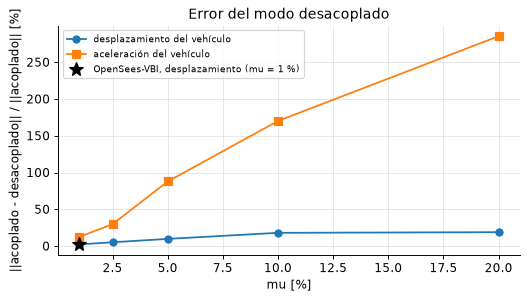

mu =   1.0 %: desplazamiento   2.3 %, aceleración   12.6 %
mu =   2.5 %: desplazamiento   5.2 %, aceleración   29.8 %
mu =   5.0 %: desplazamiento   9.7 %, aceleración   87.8 %
mu =  10.0 %: desplazamiento  18.0 %, aceleración  170.1 %
mu =  20.0 %: desplazamiento  18.9 %, aceleración  285.4 %


In [13]:
masses = [1200.0, 3000.0, 6000.0, 12000.0, 24000.0]
mus, gap_disp, gap_acc = [], [], []
for mass in masses:
    out = {}
    for interaction in ("coupled", "decoupled"):
        over = {"simulation.interaction": interaction, "vehicle.sprung_mass.mass": mass,
                "vehicle.sprung_mass.stiffness": mass * (2 * np.pi * 3.2487) ** 2}
        r = vbs.simulate(vbs.load_preset("yang2004_benchmark", over), 0, return_internal=True)
        win = r.internal["window"]
        out[interaction] = (r.internal["response"].z[win, 0, 0], r.measured)
    mus.append(r.metadata["mass_ratio"])
    gap = lambda a, b: np.linalg.norm(a - b) / np.linalg.norm(a)
    gap_disp.append(gap(out["coupled"][0], out["decoupled"][0]))
    gap_acc.append(gap(out["coupled"][1], out["decoupled"][1]))
sel = ref["coupled_time"] <= 4.0
ref_gap = np.linalg.norm(ref["coupled_vehicle_disp"][sel] - ref["decoupled_vehicle_disp"][sel]) / np.linalg.norm(ref["coupled_vehicle_disp"][sel])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.array(mus) * 100, np.array(gap_disp) * 100, "o-", label="desplazamiento del vehículo")
ax.plot(np.array(mus) * 100, np.array(gap_acc) * 100, "s-", label="aceleración del vehículo")
ax.plot([1], [ref_gap * 100], "k*", ms=12, label="OpenSees-VBI, desplazamiento (mu = 1 %)")
ax.set(xlabel="mu [%]", ylabel="||acoplado - desacoplado|| / ||acoplado|| [%]", title="Error del modo desacoplado")
ax.legend(fontsize=8)
plt.show()
for mu, gd_, ga in zip(mus, gap_disp, gap_acc):
    print(f"mu = {mu * 100:5.1f} %: desplazamiento {gd_ * 100:5.1f} %, aceleración {ga * 100:6.1f} %")

Con $\mu = 1$ % los desplazamientos son casi idénticos: unos 2 % de diferencia, el mismo valor que separa los dos modos del framework de referencia (estrella). Al crecer $\mu$, la diferencia crece, como en el estudio paramétrico de Talebi-Kalaleh & Mei (2026). En aceleración la diferencia es mayor, porque la masa del vehículo baja un poco la frecuencia del sistema acoplado (el corrimiento de frecuencia que se usa en detección de daño) y el desfase se acumula. En los rangos por defecto, $\mu$ queda entre 0.03 % y 1 %, así que el modo desacoplado sería una buena aproximación para el desplazamiento. Aun así, el modo por defecto es el acoplado, porque además capta cómo las fuerzas dinámicas de la rugosidad hacen vibrar el puente.

**Contenido espectral esperado (Yang et al., 2004).** Para un puente sin amortiguamiento bajo una carga móvil, $q_n(t) \propto \sin(n\pi v t/L) - S_n\sin(\omega_n t)$, y el contacto ve $\phi_n(vt)\,q_n(t)$. Por identidades trigonométricas, la respuesta del vehículo contiene:

$$f_v,\qquad n\frac{v}{L}=2n\,f_d,\qquad f_{bn}\pm n\frac{v}{2L}=f_{bn}\pm n f_d,\qquad f_d=\frac{v}{2L} \tag{19}$$

$f_d$ es la frecuencia de paso (la de la carga $\sin(\pi vt/L)$). La parte cuasiestática aparece al doble, en $v/L$. Las frecuencias del puente aparecen desplazadas en $\pm n f_d$.

Las dos frecuencias desplazadas están separadas por $v/L$, que es exactamente el inverso de la duración del cruce, $T_c = L/v$, es decir, el límite de resolución del tramo registrado sobre el puente. **En un solo cruce nunca se ven como dos picos separados**, sino como un pico ensanchado alrededor de $f_{bn}$. La prueba `test_vehicle_response_contains_the_theoretical_frequencies` verifica (19) de otra forma: ajusta la respuesta sobre el puente con una base de senos y cosenos que solo contiene esas frecuencias y obtiene $R^2 > 0.999$, que cae por debajo de 0.9 si se quitan las frecuencias desplazadas.

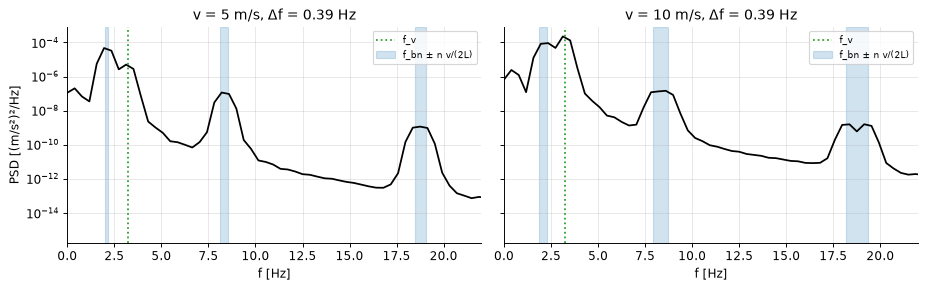

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, v in zip(axs, (5.0, 10.0)):
    r = vbs.simulate(vbs.load_preset("yang2004_benchmark", {"crossing.speed": v}), 0)
    f, pxx = welch_psd(r.measured, r.fs, nperseg=512)
    ax.semilogy(f, pxx, color="k")
    md_ = r.metadata
    fd = md_["driving_frequency"]
    ax.axvline(md_["vehicle_frequencies"][0], color="tab:green", ls=":", label="f_v")
    for n, fb in enumerate(md_["bridge_frequencies"][:3], start=1):
        ax.axvspan(fb - n * fd, fb + n * fd, color="tab:blue", alpha=0.2, label="f_bn ± n v/(2L)" if n == 1 else None)
    ax.set(xlim=(0, 22), xlabel="f [Hz]", title=f"v = {v:.0f} m/s, Δf = {f[1]:.2f} Hz")
    ax.legend(fontsize=8)
axs[0].set_ylabel("PSD [(m/s²)²/Hz]")
plt.tight_layout()
plt.show()

**Lo que sale.** A 5 m/s el espectro está dominado por los modos del puente (picos dentro de las bandas azules, el primero cerca de $f_{b1} - f_d$) y la frecuencia del vehículo no aparece como pico propio: a baja velocidad la entrada al puente es suave y casi no excita la vibración libre del vehículo. A 10 m/s la frecuencia del vehículo sí aparece. Esto coincide con la recomendación de Yang et al. (2004) de usar velocidades bajas para extraer frecuencias del puente.

## 6. Motor y rueda

**Motor.** En un motor de cuatro tiempos, cada cilindro se enciende una vez cada dos vueltas, así que la frecuencia de encendido es

$$f_{\text{fire}}=\frac{\text{rpm}\cdot N_{\text{cyl}}}{120} \tag{20}$$

que corresponde al orden $o = N_{\text{cyl}}/2$: el segundo orden para 4 cilindros, entre 20 y 200 Hz para 600 a 6000 rpm (Burdzik). La fuerza sobre la carrocería se modela como una suma de órdenes (el de encendido, su doble y un medio orden pequeño) con un rpm que varía lentamente:

$$F_e(t)=\sum_k A_k\sin\big(\Phi_k(t)\big),\qquad \Phi_k(t)=2\pi\,o_k\int_0^t\frac{\text{rpm}(\tau)}{60}\,d\tau+\varphi_k \tag{21}$$

La fase integra la frecuencia instantánea $o_k\,\text{rpm}(t)/60$. Escribir $2\pi f(t)\,t$ sería un error, porque introduciría una frecuencia que no existe. El rpm es un proceso gaussiano suave, con correlación $\exp(-(\Delta t/\tau)^2)$, $\tau = 2$ s y una desviación del 5 % de la media [SUPUESTO].

**Amplitud [SUPUESTO].** No hay un valor confirmado para autos de pasajeros. Como el sistema es lineal, se simula con amplitudes relativas y luego se escala para que la RMS de la aceleración resultante en la carrocería, a $f_{s,\text{sim}}$, sea la pedida (0.005–0.1 m/s², log-uniforme):

$$A_k = s_e\,a_k,\qquad s_e=\frac{\text{RMS}_{\text{objetivo}}}{\text{RMS}\big(\mathcal{G}_e[F_e]\big|_{s_e=1}\big)} \tag{22}$$

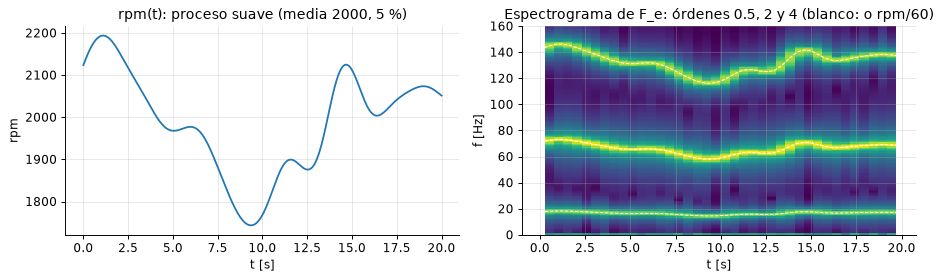

In [15]:
t = np.arange(0, 20, 1e-3)
orders = vb_engine.EngineOrders.from_config(4, 1.0, 0.3, 0.1)
force, rpm = vb_engine.engine_force(np.random.default_rng(SEED), t, orders, 2000.0, 0.05, 2.0)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(t, rpm)
axs[0].set(xlabel="t [s]", ylabel="rpm", title="rpm(t): proceso suave (media 2000, 5 %)")
from scipy.signal import spectrogram
fs_, ts_, sxx = spectrogram(force, fs=1000, window="hann", nperseg=1024, noverlap=512)
axs[1].pcolormesh(ts_, fs_, 10 * np.log10(sxx + 1e-12), shading="auto")
for o in orders.orders:
    axs[1].plot(t[::200], o * rpm[::200] / 60, "w--", lw=0.8)
axs[1].set(ylim=(0, 160), xlabel="t [s]", ylabel="f [Hz]", title="Espectrograma de F_e: órdenes 0.5, 2 y 4 (blanco: o rpm/60)")
plt.tight_layout()
plt.show()

**Aliasing.** Con $f_{s,\text{out}} = 100$ o 200 Hz, buena parte de la excitación del motor queda por encima de la frecuencia de Nyquist. Un tono de frecuencia $f$ muestreado a $f_s$ aparece en la frecuencia doblada

$$f_{\text{alias}}=\left|f-k\,f_s\right|,\qquad k=\operatorname{round}(f/f_s) \tag{23}$$

Por eso la herramienta simula a una frecuencia interna alta (1000 Hz) y modela de forma explícita el filtro anti-alias del teléfono antes del diezmado. Ejemplo: motor de 4 cilindros a 3600 rpm, encendido en 120 Hz. A 200 Hz se dobla a 80 Hz y a 100 Hz se dobla a 20 Hz, justo en la banda de interés.

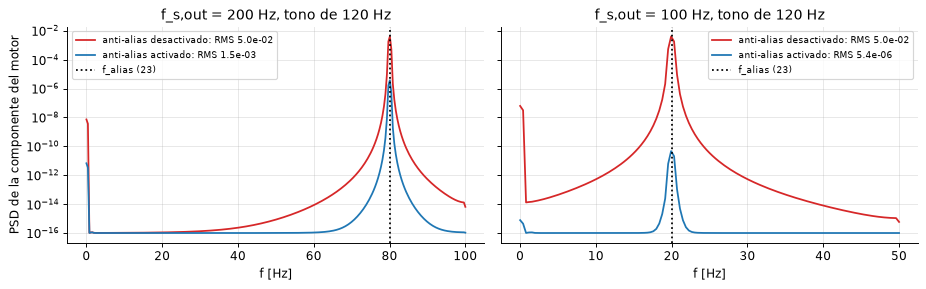

In [16]:
quiet = {"roughness.enabled": False, "sensor.white_noise.enabled": False, "sensor.quantization.enabled": False,
         "engine.n_cylinders": 4, "engine.rpm_mean": 3600.0, "engine.rpm_relative_std": 0.0,
         "engine.double_firing_amplitude": 0.0, "engine.half_order_amplitude": 0.0, "engine.body_accel_rms": 0.05}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, fs_out in zip(axs, (200.0, 100.0)):
    for aa, color in ((False, "tab:red"), (True, "tab:blue")):
        r = vbs.simulate(vbs.load_preset("typical_car_smartphone", {**quiet, "simulation.fs_out": fs_out,
                                                                     "simulation.n_samples_out": int(10.24 * fs_out),
                                                                     "sensor.anti_alias.enabled": aa}), SEED)
        f, pxx = welch_psd(r.components["engine"], r.fs, nperseg=512 if fs_out == 200 else 256)
        ax.semilogy(f, pxx + 1e-16, color=color, label=f"anti-alias {'activado' if aa else 'desactivado'}: RMS {rms(r.components['engine']):.1e}")
    ax.axvline(abs(120 - round(120 / fs_out) * fs_out), color="k", ls=":", label="f_alias (23)")
    ax.set(xlabel="f [Hz]", title=f"f_s,out = {fs_out:.0f} Hz, tono de 120 Hz")
    ax.legend(fontsize=8)
axs[0].set_ylabel("PSD de la componente del motor")
plt.tight_layout()
plt.show()

Sin filtro, el tono de 120 Hz aparece completo en 80 Hz (a 200 Hz) o en 20 Hz (a 100 Hz). Con el Butterworth de orden 4 en $0.4 f_{s,\text{out}}$, aplicado hacia adelante y hacia atrás, el tono se atenúa en $|H(120)|^2$: unos 30 dB a 200 Hz, porque 120 Hz está a solo 1.5 veces el corte de 80 Hz, y unos 80 dB a 100 Hz (corte de 40 Hz). Ningún filtro real es una pared perfecta, así que un remanente doblado siempre queda.

**Excentricidad de la rueda** (desactivada por defecto). Un desbalance o una excentricidad radial producen un desplazamiento armónico en el contacto, a la frecuencia de giro de la rueda:

$$e(t)=A_w\sin(2\pi f_w t+\psi),\qquad f_w=\frac{v}{\pi D} \tag{24}$$

$D$ es el diámetro de la llanta y $A_w$ la amplitud [SUPUESTO, 0.1–0.5 mm]. Por ejemplo, una llanta de 835 mm a 64 km/h gira a 6.8 Hz.

In [17]:
from vehicle_bridge_signal.disturbances import wheel_frequency
print(f"f_w(64 km/h, D = 0.835 m) = {wheel_frequency(64 / 3.6, 0.835):.2f} Hz")
r = vbs.simulate(vbs.load_preset("typical_car_smartphone", {"wheel.enabled": True, "wheel.diameter_m": 0.65,
                                                            "wheel.eccentricity_m": 3e-4}), SEED)
f, pxx = welch_psd(r.components["wheel"], r.fs, nperseg=1024)
print(f"v = {r.metadata['speed']} m/s, D = 0.65 m -> f_w = {r.metadata['wheel_frequency']:.2f} Hz; "
      f"pico de la componente 'wheel' en {f[np.argmax(pxx)]:.2f} Hz (Δf = {f[1]:.2f} Hz); RMS = {rms(r.components['wheel']):.3f} m/s²")

f_w(64 km/h, D = 0.835 m) = 6.78 Hz


v = 15.0 m/s, D = 0.65 m -> f_w = 7.35 Hz; pico de la componente 'wheel' en 7.42 Hz (Δf = 0.20 Hz); RMS = 0.076 m/s²


## 7. Cadena de medición del smartphone

Las etapas se aplican en este orden y cada una se puede activar o desactivar:

1. aceleración verdadera en el punto del sensor, a $f_{s,\text{sim}} = 1000$ Hz;
2. filtro del soporte del teléfono, si está activo: un grado de libertad excitado en la base, con frecuencia $f_m$ y amortiguamiento $\zeta_m$ [SUPUESTO]:
$$H_m(s)=\frac{2\zeta_m\omega_m s+\omega_m^2}{s^2+2\zeta_m\omega_m s+\omega_m^2} \tag{25}$$
3. ruido del sensor. El ruido blanco tiene una densidad espectral $ND$ en µg/√Hz (unilateral). Muestreado a $f_s$, su desviación estándar es
$$\sigma=ND\cdot g\cdot\sqrt{f_s/2} \tag{26}$$
y su PSD es plana, igual a $(ND\,g)^2$. Opcionalmente se agregan ruido rosa ($1/f$), un sesgo constante y una deriva tipo caminata aleatoria;
4. filtro anti-alias Butterworth de orden 4 con corte en $0.4 f_{s,\text{out}}$, aplicado con `sosfiltfilt` (fase cero);
5. diezmado a $f_{s,\text{out}}$ (200 Hz por defecto);
6. variación del intervalo de muestreo (*jitter*), si está activa: se remuestrea en instantes $kT + \delta_k$;
7. cuantización y saturación, con paso
$$\Delta = \frac{2\cdot\text{rango}}{2^{\text{bits}}} \tag{27}$$
Por ejemplo, el MPU-6500 tiene 16 bits en ±2 g, es decir, $\Delta = g/16384$. El eje z en reposo lee $+1\,g$, así que el rango dinámico efectivo es $[-3g, +1g)$.

La celda siguiente sigue una misma señal por las etapas.

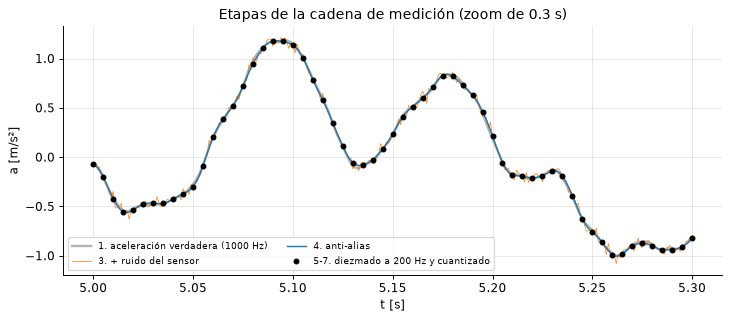

ND = 150.0 ug/sqrt(Hz): sigma a 1000 Hz = 0.0329 m/s² (ec. 26); RMS simulada = 0.0329 m/s²
paso de cuantización = 5.99e-04 m/s² (16 bits, ±2 g)


In [18]:
r = vbs.simulate("typical_car_smartphone", SEED, return_internal=True)
it = r.internal
t_sim, oi = it["t_sim"], it["out_index"]
zoom = (t_sim >= 5.0) & (t_sim <= 5.3)
zo = (r.t >= 5.0) & (r.t <= 5.3)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t_sim[zoom], it["true_sim"][zoom], color="0.7", lw=2, label="1. aceleración verdadera (1000 Hz)")
ax.plot(t_sim[zoom], (it["true_sim"] + it["noise_sim"])[zoom], color="tab:orange", lw=0.6, label="3. + ruido del sensor")
ax.plot(t_sim[zoom], it["measured_filtered_sim"][zoom], color="tab:blue", lw=1.2, label="4. anti-alias")
ax.plot(r.t[zo], r.measured[zo], "ko", ms=4, label="5-7. diezmado a 200 Hz y cuantizado")
ax.set(xlabel="t [s]", ylabel="a [m/s²]", title="Etapas de la cadena de medición (zoom de 0.3 s)")
ax.legend(fontsize=8, ncol=2)
plt.show()
nd = r.metadata["noise_density_ug"]
print(f"ND = {nd} ug/sqrt(Hz): sigma a 1000 Hz = {vb_sensor.white_noise_sigma(nd, 1000.0):.4f} m/s² (ec. 26); "
      f"RMS simulada = {rms(it['noise_sim']):.4f} m/s²")
print(f"paso de cuantización = {4 * G / 2**16:.2e} m/s² (16 bits, ±2 g)")

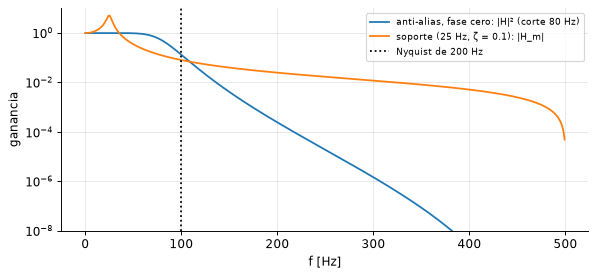

In [19]:
from scipy import signal
fig, ax = plt.subplots(figsize=(8, 3.4))
f = np.linspace(0.1, 499, 4000)
_, h_aa = signal.sosfreqz(vb_sensor.antialias_sos(4, 80.0, 1000.0), worN=f, fs=1000.0)
_, h_m = signal.sosfreqz(vb_sensor.mount_sos(25.0, 0.1, 1000.0), worN=f, fs=1000.0)
ax.semilogy(f, np.abs(h_aa) ** 2, label="anti-alias, fase cero: |H|² (corte 80 Hz)")
ax.semilogy(f, np.abs(h_m), label="soporte (25 Hz, ζ = 0.1): |H_m|")
ax.axvline(100, color="k", ls=":", label="Nyquist de 200 Hz")
ax.set(xlabel="f [Hz]", ylabel="ganancia", ylim=(1e-8, 10))
ax.legend(fontsize=8)
plt.show()

**El margen de 5 a 10 veces.** En CIV E 789 (Lecture 2) se mencionó que la señal útil de un smartphone queda solo de 5 a 10 veces por encima de su ruido. La celda siguiente compara la componente del puente con el ruido blanco del sensor, sobre el puente, en el escenario típico.

In [20]:
m = r.metadata
print(f"RMS sobre el puente: componente del puente = {m['rms_bridge_on']:.2e} m/s², ruido blanco = {m['rms_white_noise_on']:.2e} m/s²")
print(f"puente / ruido = {10 ** (m['ratio_db_bridge_to_white_noise'] / 20):.2f} veces ({m['ratio_db_bridge_to_white_noise']:.1f} dB)")

RMS sobre el puente: componente del puente = 1.01e-03 m/s², ruido blanco = 1.20e-02 m/s²
puente / ruido = 0.08 veces (-21.5 dB)


Con un carro liviano (450 kg sobre un puente de 300 t, $\mu \approx 0.15$ %), la componente del puente queda **por debajo** del ruido del sensor, lejos del margen de 5 a 10 veces. Es el resultado físico con los rangos de la sección 6: el puente casi no se deflecta bajo un auto. La sección 9 muestra que esto se repite en todo el dataset por defecto. Para los proyectos que necesiten un margen controlado existe el modo `snr_controlled` (sección 8), cuyo preset fija el puente entre 5 y 10 veces por encima del ruido blanco.

## 8. Descomposición exacta en componentes

Dada la trayectoria, el vehículo es un sistema **lineal e invariante** cuya entrada es el desplazamiento del contacto $u_c$ más la fuerza del motor. Por lo tanto, la aceleración medida se separa **exactamente** según el camino por el que llega:

$$\ddot y_s=\sum_{n=1}^{N}\mathcal{G}\Big[\phi_n\big(x_a(t)\big)\,q_n(t)\Big]+\mathcal{G}\big[r\big(x_a(t)\big)\big]+\mathcal{G}\big[e(t)\big]+\mathcal{G}_e\big[F_e\big] \tag{28}$$

$\mathcal{G}$ es el operador del vehículo, de desplazamiento del contacto a aceleración de la carrocería (con su velocidad consistente, ec. 16), y $\mathcal{G}_e$ el de la fuerza del motor a esa aceleración. La descomposición vale **también en el modo acoplado**: los $q_n$ ya contienen la retroalimentación, y basta con volver a pasar cada parte de $u_c$ por el modelo del vehículo, con el mismo integrador de Newmark. La herramienta verifica en cada muestra que la suma de los caminos reproduce la solución acoplada (`decomposition_residual`, del orden de $10^{-14}$).

Reglas de las etiquetas:

- `bridge_mode_1` … `bridge_mode_K` ($K = 3$ por defecto) y `bridge_higher_modes` incluyen la parte cuasiestática (la deflexión que sigue al vehículo, en $v/L$) y la parte dinámica de cada modo. Antes de que el primer eje entre valen exactamente cero, por causalidad. Después de la salida contienen la vibración libre del vehículo que el puente excitó, que también es respuesta al puente.
- Las componentes limpias pasan por las **mismas etapas lineales deterministas** que la medición (soporte, anti-alias y diezmado), pero no por el ruido, el jitter ni la cuantización. Así, `measured` = suma de las componentes se cumple exactamente, y `noise` es el residuo: ruido del sensor, cuantización, jitter y deriva. Si todas esas etapas están apagadas, `noise` vale exactamente cero.
- Las mismas componentes se guardan para la aceleración del punto de contacto, por eje.

**Modo `snr_controlled`.** Como el sistema es lineal, cada fuente de excitación (peso, rugosidad, motor, rueda, vibración ambiental) se resuelve en su propia columna y la señal total es una suma ponderada de columnas. En el modo `physical` todos los pesos valen 1, salvo el del motor, que fija su RMS en la carrocería (ec. 22). En el modo `snr_controlled` el sensor conserva su densidad de ruido $ND$ y su cuantización físicas, y los pesos se eligen así:

- las entradas que excitan al puente (peso y vibración ambiental) se multiplican por un factor común $s_b$, de modo que la componente del puente quede $\text{SNR}_{\text{ruido}}$ dB por encima del ruido blanco del sensor;
- cada perturbación $j$ (rugosidad, motor, rueda) se multiplica por $s_j$, de modo que

$$20\log_{10}\frac{\text{RMS}_{\text{puente}}(s_b, s)}{s_j\,\text{RMS}(D_j)}=\text{SNR}_j^{\text{objetivo}} \tag{29}$$

Todo se mide solo sobre el puente y a $f_{s,\text{out}}$. Como la retroalimentación de cada perturbación también cambia un poco la componente del puente, (29) se resuelve por iteración de punto fijo. Las relaciones logradas y los factores ($s_b$ = `scale_bridge_inputs`) quedan en los metadatos. La señal sigue siendo la respuesta del mismo sistema lineal con las entradas escaladas, así que la descomposición sigue siendo exacta. Lo que deja de ser físico es la amplitud absoluta del puente: $s_b$ suele valer cientos, como si el puente estuviera mucho más excitado que por un auto. Por eso el sensor se deja físico: así las amplitudes de la señal (puente de ~0.1 m/s², rugosidad de 0.1 a 1 m/s²) quedan muy por encima del paso de cuantización.

La celda siguiente activa todas las perturbaciones (rueda, vibración ambiental, soporte) y usa `snr_controlled` para que el puente sea visible.

identidad |measured - suma| / RMS = 0.0e+00; residuo de la descomposición = 1.3e-14
  puente / roughness    =  -6.00 dB
  puente / engine       =   6.00 dB
  puente / wheel        =  -0.00 dB
  puente / white_noise  =  16.00 dB


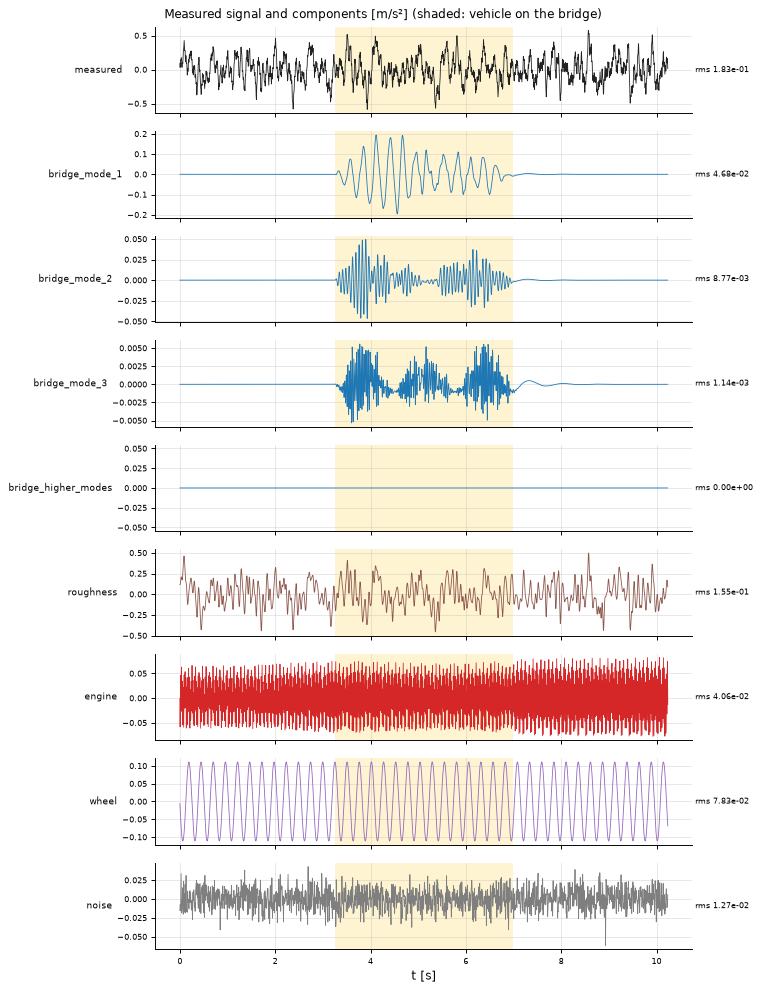

In [21]:
rich_over = {"wheel.enabled": True, "wheel.diameter_m": 0.65, "wheel.eccentricity_m": 3e-4,
             "ambient.enabled": True, "ambient.modal_accel_rms": 0.005,
             "mount.enabled": True, "mount.frequency_hz": 25.0, "mount.damping_ratio": 0.1,
             "simulation.amplitude_mode": "snr_controlled", "crossing.speed": 8.0,
             "snr_control.targets_db.roughness": -6.0, "snr_control.targets_db.engine": 6.0,
             "snr_control.targets_db.wheel": 0.0, "snr_control.targets_db.sensor_noise": 16.0}
rich = vbs.simulate(vbs.load_preset("typical_car_smartphone", rich_over), SEED)
mm = rich.metadata
print(f"identidad |measured - suma| / RMS = {rich.identity_error():.1e}; residuo de la descomposición = {mm['decomposition_residual']:.1e}")
for kind in ("roughness", "engine", "wheel", "white_noise"):
    print(f"  puente / {kind:<12} = {mm[f'ratio_db_bridge_to_{kind}']:6.2f} dB")
fig = plot_components(rich)
plt.show()

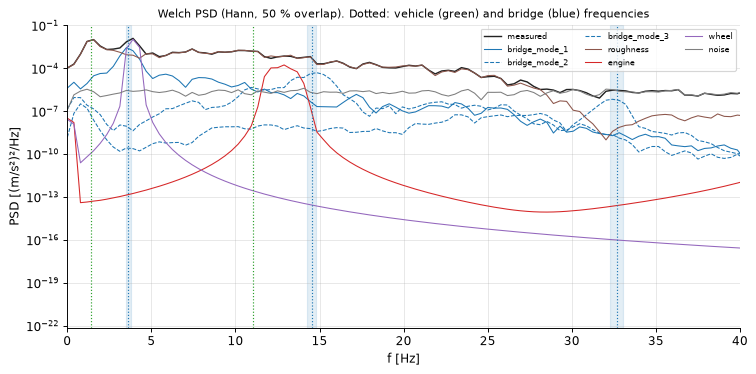

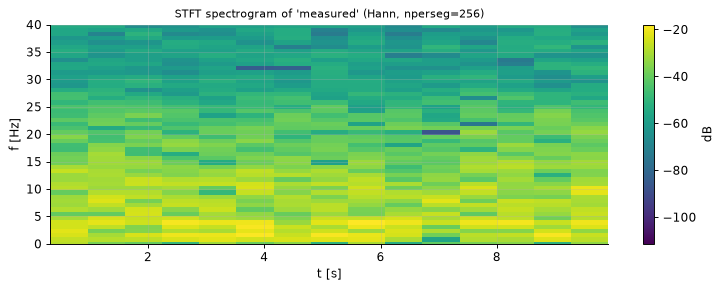

In [22]:
fig = plot_component_spectra(rich, fmax=40)
ax = fig.axes[0]
fd = mm["driving_frequency"]
for n, fb in enumerate(mm["bridge_frequencies"][:3], start=1):
    ax.axvspan(fb - n * fd, fb + n * fd, color="tab:blue", alpha=0.12)
plt.show()
fig = plot_spectrogram(rich, "measured", nperseg=256, fmax=40)
plt.show()

En el espectro, cada componente ocupa su propia banda: la rugosidad se concentra cerca del rebote del vehículo (1.4 Hz) y del salto de rueda, la rueda en $f_w$, el motor en sus órdenes, y cada modo del puente alrededor de $f_{bn}$ (bandas azules de ancho $\pm n f_d$). En el espectrograma, el puente solo aporta energía durante el cruce, mientras que las perturbaciones están presentes en toda la ventana. Esa diferencia la puede aprovechar un método de separación, por ejemplo el filtro inverso con el espectro fuera del puente.

**Punto de contacto (Yang et al., 2018).** La aceleración del punto de contacto, $\ddot u_c$, no contiene la frecuencia del vehículo, porque es la entrada del vehículo y no su respuesta. La herramienta la guarda por eje como salida auxiliar. Con el pavimento liso se compara la componente del puente en la carrocería y en el contacto:

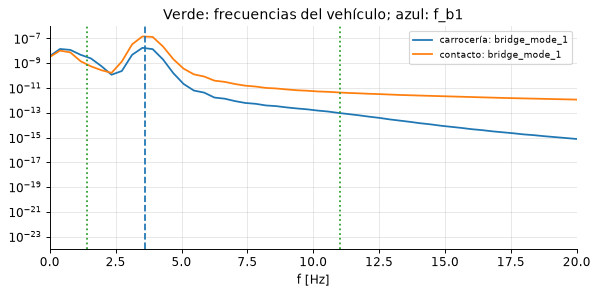

In [23]:
r = vbs.simulate("bridge_only_smooth", SEED)
f, p_body = welch_psd(r.components["bridge_mode_1"], r.fs, nperseg=512)
_, p_cont = welch_psd(r.contact["bridge_mode_1"][0], r.fs, nperseg=512)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.semilogy(f, p_body, label="carrocería: bridge_mode_1")
ax.semilogy(f, p_cont, label="contacto: bridge_mode_1")
for fv in r.metadata["vehicle_frequencies"]:
    ax.axvline(fv, color="tab:green", ls=":")
ax.axvline(r.metadata["bridge_frequencies"][0], color="tab:blue", ls="--")
ax.set(xlim=(0, 20), xlabel="f [Hz]", title="Verde: frecuencias del vehículo; azul: f_b1")
ax.legend(fontsize=8)
plt.show()

## 9. El dataset

`generate_dataset(config, n_samples, out_path, seed, workers)` genera muchos cruces con parámetros aleatorios y los guarda en HDF5. Puntos clave:

- **Muestreo.** Cada parámetro definido como distribución en el YAML (uniforme, log-uniforme, normal truncada o elección) se muestrea de forma independiente, con su propio generador derivado de la semilla base y del nombre del parámetro. Así, cambiar un rango no altera los demás sorteos.
- **Puentes y vehículos reutilizados.** Los parámetros de puente y de vehículo se sortean por `bridge_id` y `vehicle_id`, y cada muestra combina un puente y un vehículo de esos grupos con su propio cruce (velocidad, rugosidad, rpm, ruido...). Con `dataset.partitions` los puentes y vehículos se reparten en grupos disjuntos (70/15/15 % en `default_dataset`), y la función `group_split` devuelve una división en entrenamiento, validación y prueba **sin compartir puentes ni vehículos y sin descartar muestras**.
- **Reproducibilidad.** La muestra `i` usa la semilla `SeedSequence(base_seed, spawn_key=(2, i))`. El resultado es idéntico bit a bit con 1 o con N procesos, y se verifica en las pruebas.
- **Rechazo.** Si el cruce no cabe en la ventana, se vuelve a muestrear la velocidad (nunca se recorta el cruce). Si las frecuencias objetivo del vehículo son imposibles (ec. 7), se vuelven a muestrear.
- **Formato.** `measured`, cada componente, las componentes en el contacto, las máscaras `on_bridge` y la respuesta del puente al centro, en `float32` con un fragmento por muestra; una tabla de metadatos; y la configuración YAML completa, el commit y `schema_version` como atributos (ver el README).

Para este cuaderno se generan 400 muestras con el preset por defecto (amplitudes físicas) y 400 con `snr_controlled_dataset`, en una carpeta temporal: la herramienta no guarda datasets dentro de `tools/`.

In [24]:
tmp = Path(tempfile.mkdtemp(prefix="vbsig_nb_"))
workers = min(8, os.cpu_count() or 1)
paths = {}
for name in ("default_dataset", "snr_controlled_dataset"):
    t0 = time.time()
    paths[name] = vbs.generate_dataset(name, 400, tmp / f"{name}.h5", seed=SEED, workers=workers, progress=False)
    print(f"{name}: 400 muestras en {time.time() - t0:.0f} s con {workers} procesos -> {paths[name].stat().st_size / 1e6:.1f} MB")
ds = vbs.load_dataset(paths["default_dataset"])
dsn = vbs.load_dataset(paths["snr_controlled_dataset"])
print(ds)
meta = ds.metadata

default_dataset: 400 muestras en 31 s con 8 procesos -> 31.6 MB


snr_controlled_dataset: 400 muestras en 31 s con 8 procesos -> 31.4 MB
VBIDataset('C:\Users\amilc\AppData\Local\Temp\vbsig_nb_j7ks455j\default_dataset.h5', n=400, T=2048, fs=200.0 Hz, components=['bridge_mode_1', 'bridge_mode_2', 'bridge_mode_3', 'bridge_higher_modes', 'roughness', 'engine', 'wheel', 'noise'])


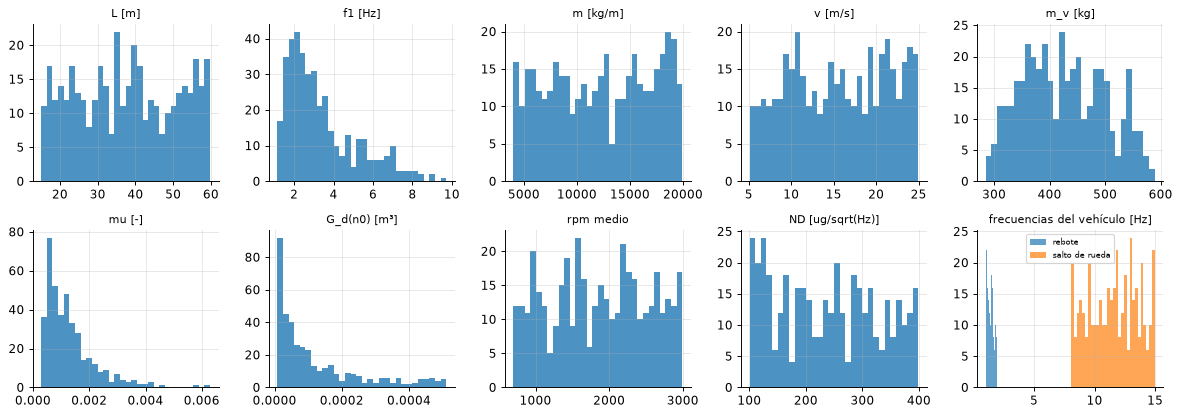

clases de rugosidad: {'A': np.int64(117), 'B': np.int64(150), 'C': np.int64(133)} | puentes: 400 | vehículos: 200


In [25]:
fields = [("span", "L [m]"), ("f1", "f1 [Hz]"), ("mass_per_length", "m [kg/m]"), ("speed", "v [m/s]"),
          ("vehicle_mass", "m_v [kg]"), ("mass_ratio", "mu [-]"), ("roughness_gd_n0", "G_d(n0) [m³]"),
          ("engine_rpm_mean", "rpm medio"), ("noise_density_ug", "ND [ug/sqrt(Hz)]")]
fig, axs = plt.subplots(2, 5, figsize=(14, 5))
for ax, (key, label) in zip(axs.flat, fields):
    v = np.asarray(meta[key], float)
    ax.hist(v[np.isfinite(v)], bins=30, color="tab:blue", alpha=0.8)
    ax.set_title(label, fontsize=9)
vf = meta["vehicle_frequencies"]
axs.flat[-1].hist(vf[:, 0], bins=30, alpha=0.7, label="rebote")
axs.flat[-1].hist(vf[:, 1], bins=30, alpha=0.7, label="salto de rueda")
axs.flat[-1].set_title("frecuencias del vehículo [Hz]", fontsize=9)
axs.flat[-1].legend(fontsize=7)
plt.tight_layout()
plt.show()
classes, counts = np.unique(meta["roughness_class"], return_counts=True)
print("clases de rugosidad:", dict(zip(classes, counts)), "| puentes:", len(np.unique(meta["bridge_id"])),
      "| vehículos:", len(np.unique(meta["vehicle_id"])))

Los rangos corresponden a la sección 6. La velocidad no queda uniforme en 5–25 m/s: los cruces lentos de puentes largos no caben en la ventana de 10.24 s (con 1 s de margen a cada lado) y se vuelven a muestrear, lo que reduce un poco la proporción de velocidades bajas. Las relaciones entre el puente y cada perturbación, medidas sobre el puente, son:

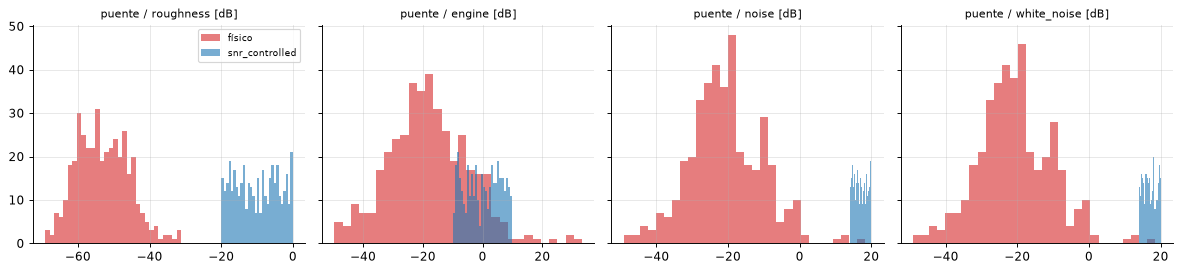

físico, puente/roughness  : mediana  -53.7 dB, percentiles 5-95:  -64.1 a  -41.0 dB
físico, puente/engine     : mediana  -18.2 dB, percentiles 5-95:  -39.8 a    2.8 dB
físico, puente/white_noise: mediana  -21.4 dB, percentiles 5-95:  -36.8 a   -3.0 dB


In [26]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.3), sharey=True)
for ax, kind in zip(axs, ("roughness", "engine", "noise", "white_noise")):
    for d, label, color in ((ds, "físico", "tab:red"), (dsn, "snr_controlled", "tab:blue")):
        v = np.asarray(d.metadata[f"ratio_db_bridge_to_{kind}"], float)
        ax.hist(v[np.isfinite(v)], bins=30, alpha=0.6, color=color, label=label)
    ax.set_title(f"puente / {kind} [dB]", fontsize=9)
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
for kind in ("roughness", "engine", "white_noise"):
    v = np.asarray(meta[f"ratio_db_bridge_to_{kind}"], float)
    print(f"físico, puente/{kind:<11}: mediana {np.nanmedian(v):6.1f} dB, percentiles 5-95: {np.nanpercentile(v, 5):6.1f} a {np.nanpercentile(v, 95):6.1f} dB")

Con amplitudes físicas, el puente queda en mediana unos 50 dB por debajo de la respuesta a la rugosidad y unos 20 dB por debajo del ruido del sensor. Separarlo así es un problema extremadamente difícil, y esa es la conclusión física de los rangos de la sección 6 con autos de pasajeros ($\mu < 1$ %). En ese régimen, la etiqueta `noise` incluye además una cuantización comparable a la propia componente del puente (paso de $6\times10^{-4}$ m/s²). El dataset `snr_controlled` lleva las relaciones a los rangos objetivo: el puente de 5 a 10 veces sobre el ruido blanco, la rugosidad entre −20 y 0 dB, y el motor y la rueda entre −10 y 10 dB.

**Muestras fáciles y difíciles.** Se ordenan por la relación entre el puente y la suma de todas las perturbaciones:

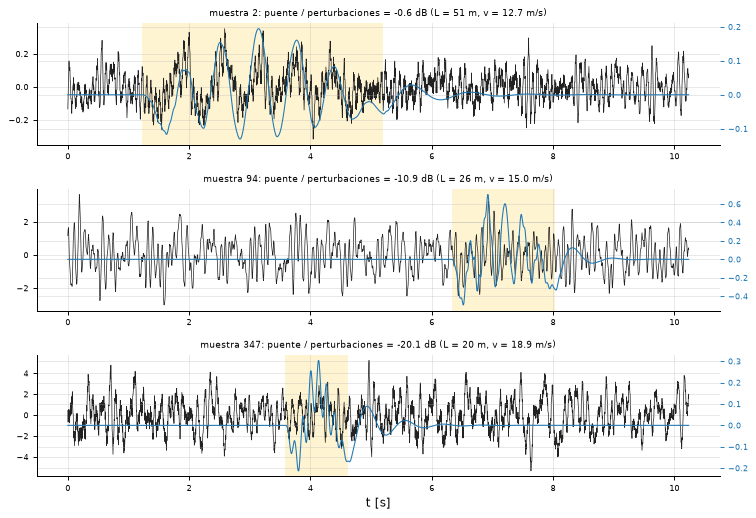

In [27]:
def total_ratio_db(d):
    mt = d.metadata
    dist = np.sqrt(np.nansum([np.nan_to_num(mt[f"rms_{k}_on"]) ** 2 for k in ("roughness", "engine", "wheel", "noise")], axis=0))
    return 20 * np.log10(mt["rms_bridge_on"] / dist)


ratio = total_ratio_db(dsn)
order = np.argsort(ratio)
picks = [order[-1], order[len(order) // 2], order[0]]
samples = [dsn.sample(i) for i in picks]
fig = plot_preview(samples, titles=[f"muestra {i}: puente / perturbaciones = {ratio[i]:.1f} dB (L = {dsn.metadata['span'][i]:.0f} m, "
                                    f"v = {dsn.metadata['speed'][i]:.1f} m/s)" for i in picks])
plt.show()

In [28]:
lift = np.asarray(meta["wheel_lift_off"], bool)
print(f"despegue de rueda en {lift.mean() * 100:.1f} % de las muestras físicas "
      f"(min_contact_force_ratio < 0); se puede filtrar con meta['min_contact_force_ratio'].")
split = vbs.group_split(ds)
print({k: len(v) for k, v in split.items()})
for a, b_ in (("train", "val"), ("train", "test"), ("val", "test")):
    shared_b = set(meta["bridge_id"][split[a]]) & set(meta["bridge_id"][split[b_]])
    shared_v = set(meta["vehicle_id"][split[a]]) & set(meta["vehicle_id"][split[b_]])
    print(f"  {a}/{b_}: puentes compartidos = {len(shared_b)}, vehículos compartidos = {len(shared_v)}")
ds.close()
dsn.close()

despegue de rueda en 13.5 % de las muestras físicas (min_contact_force_ratio < 0); se puede filtrar con meta['min_contact_force_ratio'].
{'train': 280, 'val': 60, 'test': 60, 'discarded': 0}
  train/val: puentes compartidos = 0, vehículos compartidos = 0
  train/test: puentes compartidos = 0, vehículos compartidos = 0
  val/test: puentes compartidos = 0, vehículos compartidos = 0


El despegue de rueda aparece en vías clase C a alta velocidad, en los vehículos más rígidos del rango (masa no suspendida de hasta 100 kg con salto de rueda de hasta 15 Hz, es decir, llantas de más de 500 kN/m). Queda marcado por muestra para que cada proyecto decida si lo usa. La división por grupos no comparte ningún puente ni vehículo entre conjuntos.

## 10. Supuestos y limitaciones

| Supuesto | Valor | Justificación | Efecto esperado |
|---|---|---|---|
| Modelo plano 2D | un solo plano vertical; el cuarto de carro es toda la carga sobre el puente | estándar en drive-by (Yang et al. 2004; Talebi-Kalaleh & Mei 2026) | no hay torsión ni efectos transversales; $\mu$ representa un carril |
| Viga de Euler-Bernoulli simplemente apoyada | modos senoidales, $f_n = n^2 f_1$ | modelo de referencia del benchmark | sin cortante, inercia rotacional ni continuidad entre vanos |
| Superposición modal truncada | modos con $f_n \le \min(0.45 f_{s,\text{out}}, 40)$ Hz, máximo 6 | por encima no se observan a $f_{s,\text{out}}$ | error estático < 1.5 % con un modo (ec. 5) |
| $f_1$ nominal × U[0.7, 1.3] | tabla 5 de Talebi-Kalaleh & Mei (2026) | factor de dispersión [SUPUESTO] | cubre puentes más rígidos y más flexibles que el promedio |
| Amortiguamiento del puente | U[0.5 %, 3 %] por modo | [SUPUESTO]; el estudio de referencia usó 0.3 % | controla la vibración residual y la ambiental |
| Contacto puntual | sin huella; suavizado por media móvil de 0.25 m | [SUPUESTO] como en el framework de referencia | atenúa longitudes de onda < 0.25 m |
| Vehículo lineal | resortes y amortiguadores lineales; la rueda nunca se despega | estándar | con despegue (marcado en los metadatos) la respuesta real sería distinta |
| Rigideces desde frecuencias objetivo | definiciones de Gillespie (ec. 7) | rangos de frecuencia publicados | combinaciones imposibles se vuelven a muestrear |
| Amortiguamiento de suspensión | ζ U[0.2, 0.4] | [SUPUESTO] | ancho de la resonancia de rebote |
| Velocidad constante | sin frenado ni aceleración | simplificación de la especificación | el rpm varía, la velocidad no |
| Rugosidad ISO 8608 | $w = 2$, clases A–C con pesos 0.3/0.4/0.3, $G_d$ log-uniforme en la clase; límite inferior de A = 8e-6 m³ | ISO 8608; Loprencipe y Zoccali (2017); límite de A [SUPUESTO] | vías pavimentadas típicas |
| Motor | órdenes N/2 (1.0), N (0.3), 0.5 (0.1); rpm 700–3000, 5 %, τ = 2 s; RMS en la carrocería 0.005–0.1 m/s² | [SUPUESTO]; único dato: 0.77 m/s² en un camión en ralentí | nivel del motor incierto; por eso es configurable |
| Rueda, soporte, vibración ambiental, ruido rosa, sesgo, deriva, jitter | ver `defaults.yaml` | [SUPUESTO], desactivados por defecto | perturbaciones adicionales para estudios de robustez |
| Ruido del sensor | ND U[100, 400] µg/√Hz; 16 bits en ±2 g | iPhone XR 110 µg/√Hz; MPU-6500 | ruido blanco ~0.01 m/s² RMS a 200 Hz |
| Integración numérica | Newmark de aceleración promedio a 1000 Hz | estándar, sin amortiguamiento numérico | error de periodo $\approx(\omega\Delta t)^2/12$: 0.5 % a 40 Hz; usar 2000 Hz si se necesita más |
| Ventana | 2048 muestras a 200 Hz; 4 s de precalentamiento y 0.5 s de cola | precalentamiento para que la suspensión ya esté excitada al entrar | el cruce completo siempre cabe; nunca se recorta |

**Limitaciones conocidas.** Las frecuencias desplazadas $f_{bn} \pm n v/(2L)$ no se pueden resolver en un solo cruce (sección 5). El filtro anti-alias no es una pared perfecta (sección 6). Con amplitudes físicas, el puente queda muy por debajo de las perturbaciones (sección 9). La vibración ambiental es ruido blanco modal estacionario y no reproduce tráfico pesado con eventos discretos.

## Referencias

- Talebi-Kalaleh, M., & Mei, Q. (2026). *An Open-Source Framework for Coupled Vehicle-Bridge Interaction Analysis Using OpenSees*. arXiv:2605.09175. Código: https://github.com/MTalebi/OpenSees-VBI-Simulation
- Yang, Y. B., Lin, C. W., & Yau, J. D. (2004). Extracting bridge frequencies from the dynamic response of a passing vehicle. *Journal of Sound and Vibration*.
- Yang, Y. B., Zhang, B., Qian, Y., & Wu, Y. (2018). Contact-point response for modal identification of bridges by a moving test vehicle. *International Journal of Structural Stability and Dynamics*, 18(5).
- Gillespie, T. D. (1992). *Fundamentals of Vehicle Dynamics*. SAE.
- ISO 8608:2016. *Mechanical vibration — Road surface profiles — Reporting of measured data*.
- Agostinacchio, M., Ciampa, D., & Olita, S. (2014). The vibrations induced by surface irregularities in road pavements – a Matlab approach. *European Transport Research Review*.
- Loprencipe, G., & Zoccali, P. (2017). Use of generated artificial road profiles in road roughness evaluation. *Journal of Modern Transportation*.
- Komarizadehasl, S., et al. (2024). *Frontiers of Structural and Civil Engineering* (densidad de ruido del iPhone XR).
- Elhattab, A., Uddin, N., & OBrien, E. (2019). Extraction of bridge fundamental frequencies utilizing a smartphone MEMS accelerometer. *Sensors*, 19(14).
- Burdzik, R. *Identification of Vibrations in Automotive Vehicles*, cap. 11.
- Material de clase de CIV E 789 (Prof. Talebi-Kalaleh): Lectures 2, 3 y 4.